In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/netflix_cleaned.csv")
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [29]:
content_counts=df['type'].value_counts()
print(content_counts)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [30]:
content_percentages=df['type'].value_counts(normalize=True)*100
print(content_percentages)

type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64


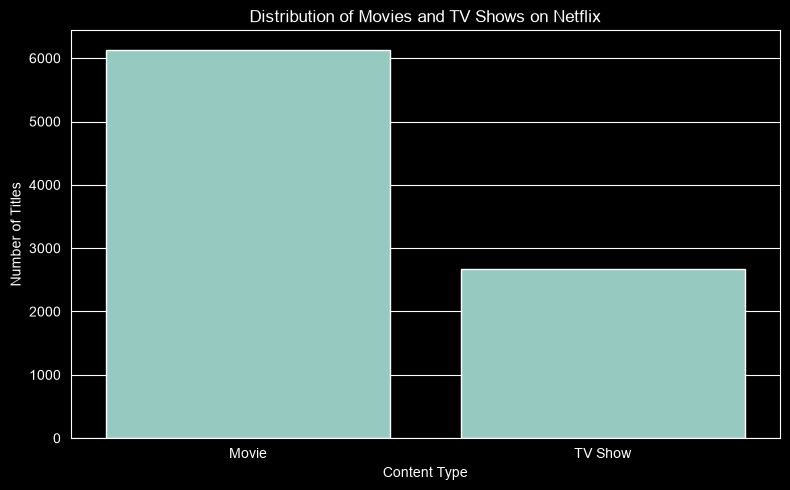

In [31]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='type')

plt.title('Distribution of Movies and TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.show()

### Task 1: Content Type Analysis — Key Findings

- The dataset contains 8,807 titles: 6,131 Movies and 2,676 TV Shows.
- Movies account for approximately 69.62% of the catalog, while TV Shows account for 30.38%.
- The catalog is more heavily represented by Movies than TV Shows.
- **Business implication:** Netflix's catalog has a larger movie selection. Further analysis can examine how the mix of content varies by release year, country, rating, and genre.

**Limitation:** These figures describe catalog composition only. They do not indicate viewing hours, popularity, subscriber preferences, or revenue.

In [32]:
print('Earliest release year:',df['release_year'].min())
print('Latest release year:',df['release_year'].max())
print('Median release year:',df['release_year'].median())
df['release_year'].describe()

Earliest release year: 1925
Latest release year: 2021
Median release year: 2017.0


count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

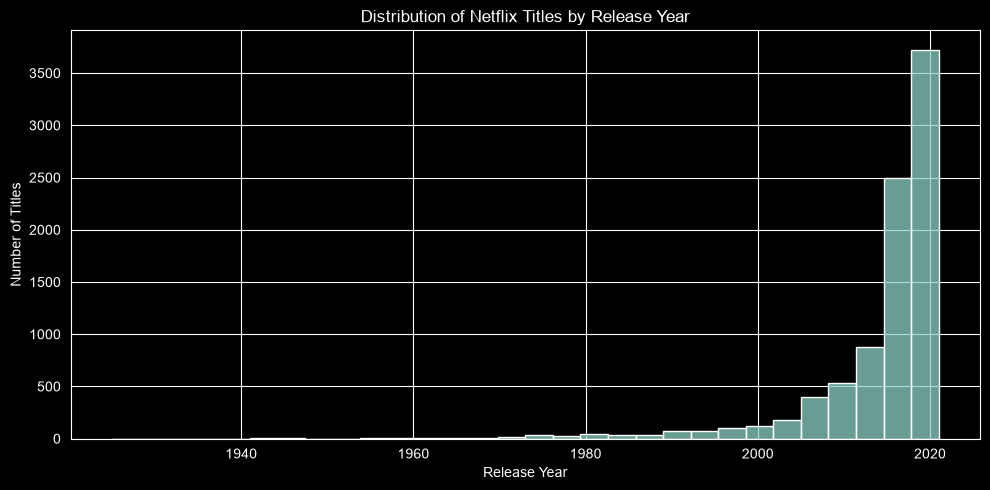

In [33]:
plt.figure(figsize=(10,5))
sns.histplot(data=df,x='release_year',bins=30)

plt.title('Distribution of Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.show()

### Task 2: Content Release Trends — Key Findings

- The dataset contains 8,807 titles released between 1925 and 2021.
- The median release year is 2017, while the mean release year is approximately 2014.
- The distribution shows a strong concentration of titles released during the 2010s, with relatively fewer titles from earlier decades.
- **Business implication:** The catalog has substantial representation of relatively recent content. Further analysis of content addition dates, genres, and countries can help explain how the catalog is structured.

**Limitation:** Release-year distribution alone cannot establish viewer preferences, content popularity, or the reasons behind Netflix's content decisions.

In [44]:
df = pd.read_csv("../data/processed/netflix_cleaned.csv")

print("Data type:", df["date_added"].dtype)
print("\nFirst 15 original date values:")
print(df["date_added"].head(15).to_list())

Data type: str

First 15 original date values:
['2021-09-25', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-24', '2021-09-23', '2021-09-23', '2021-09-22', '2021-09-22']


In [45]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="%Y-%m-%d",
    errors="coerce"
)
print("Data type:", df["date_added"].dtype)
print("Valid dates:", df["date_added"].notna().sum())
print("Missing dates:", df["date_added"].isna().sum())

Data type: datetime64[us]
Valid dates: 8797
Missing dates: 10


In [46]:
df["year_added"] = df["date_added"].dt.year
print(df["year_added"].value_counts().sort_index())

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


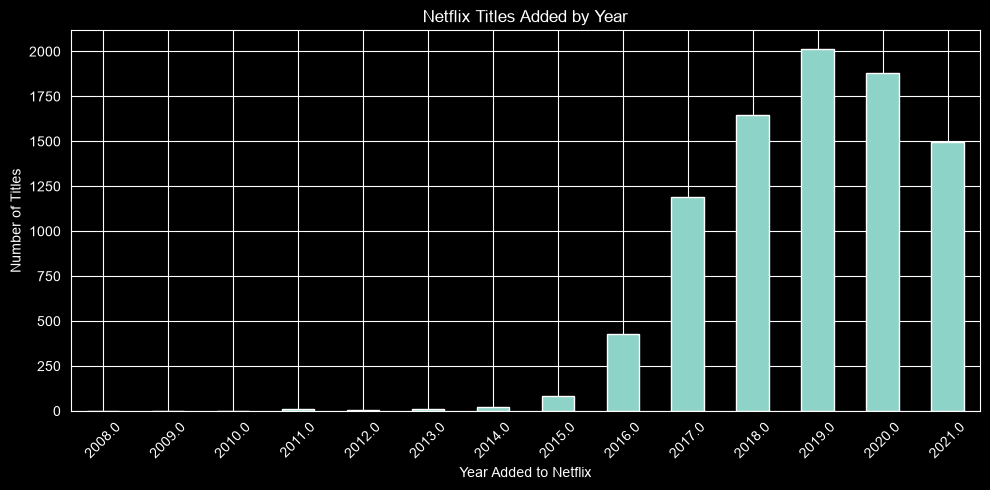

In [50]:
yearly_additions = df["year_added"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
yearly_additions.plot(kind="bar")

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 3: Netflix Content Addition Trends — Key Findings

- Netflix catalog additions increased substantially between 2015 and 2019.
- The highest number of titles was added in 2019, with 2,016 titles.
- Additions declined in 2020 and 2021.
- **Business implication:** The pattern highlights how the volume of catalog additions changed over time. Comparing Movies and TV Shows separately may help reveal which content type contributed more to these changes.

**Limitation:** The dataset records addition dates but does not explain why the trend changed. These counts do not measure viewing activity or content popularity.

In [51]:
rating_counts = df["rating"].value_counts()
print(rating_counts)

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
Unknown        7
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


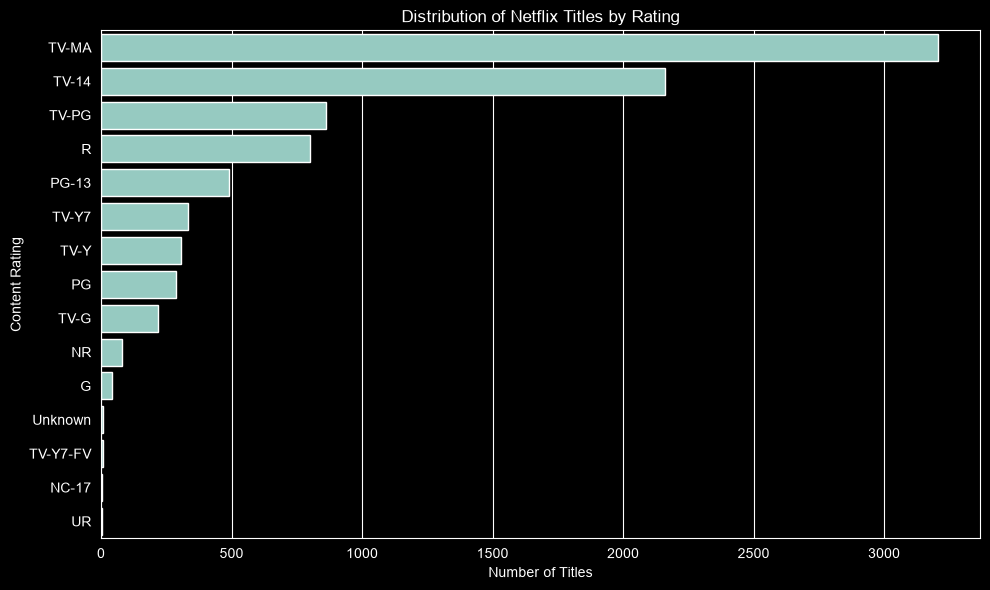

In [52]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y="rating",
    order=df["rating"].value_counts().index
)
plt.title("Distribution of Netflix Titles by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()


### Task 4: Ratings Analysis — Key Findings

- TV-MA is the most common content rating, with 3,207 titles.
- TV-14 is the second most common, with 2,160 titles.
- Together, TV-MA and TV-14 represent approximately 60.9% of the catalog.
- Other categories, including TV-PG, R, and PG-13, also have substantial representation.
- **Business implication:** The catalog contains a large proportion of titles classified for mature or teenage audiences. Analyzing ratings by content type and genre can provide a clearer picture of the catalog's composition.

**Limitation:** Content ratings indicate classification, not actual viewer demographics, preferences, or viewing activity.

In [54]:
country_counts = (
    df.loc[df["country"] != "Unknown", "country"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)
print(country_counts.head(10))

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


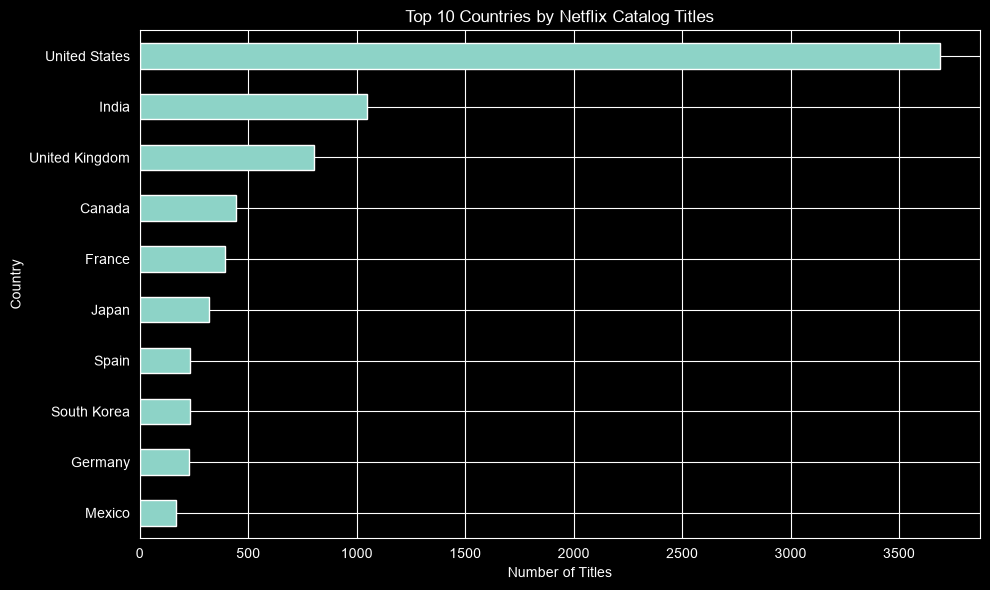

In [55]:
top_countries = country_counts.head(10).sort_values()
plt.figure(figsize=(10, 6))
top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Netflix Catalog Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Task 5: Country Analysis — Key Findings

- The United States has the highest number of title-country associations, followed by India and the United Kingdom.
- Canada, France, Japan, Spain, South Korea, Germany, and Mexico also appear among the top 10 countries.
- The catalog includes titles associated with countries across several regions.
- **Business implication:** Country-level analysis can help describe the geographic representation of the catalog. Further analysis by genre and content type could reveal differences in the types of titles associated with each country.

**Limitation:** Titles may be associated with multiple countries. These counts do not represent exclusive production totals, viewer preferences, or regional popularity.

In [56]:
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)
print(genre_counts.head(10))

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


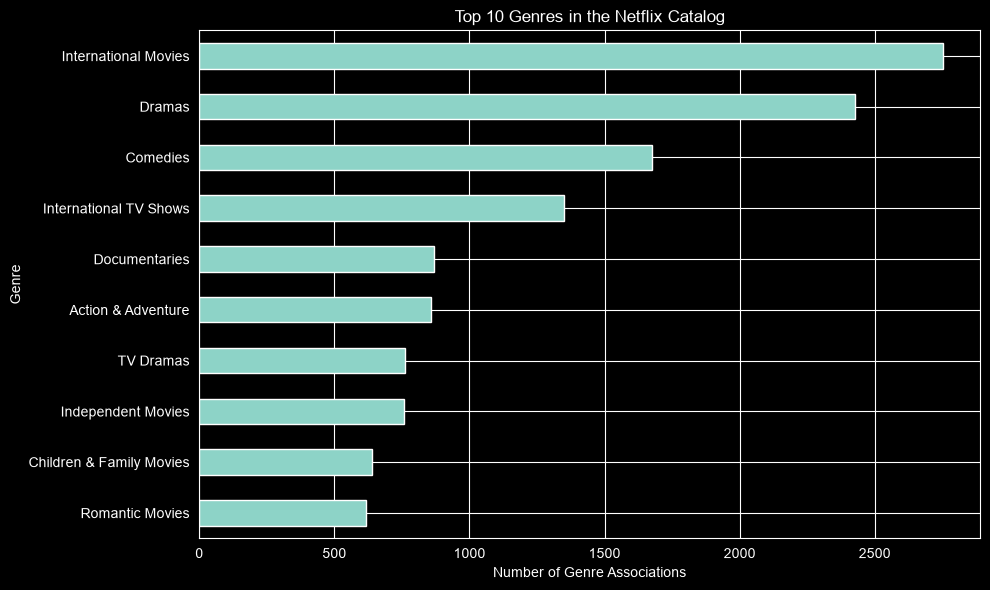

In [57]:
top_genres = genre_counts.head(10).sort_values()
plt.figure(figsize=(10, 6))
top_genres.plot(kind="barh")

plt.title("Top 10 Genres in the Netflix Catalog")
plt.xlabel("Number of Genre Associations")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

### Task 6: Genre Analysis — Key Findings

- International Movies is the most frequent category, followed by Dramas and Comedies.
- International TV Shows also has substantial representation in the catalog.
- Documentaries, Action & Adventure, TV Dramas, Independent Movies, Children & Family Movies, and Romantic Movies appear among the top 10 categories.
- **Business implication:** Genre analysis helps describe the range of content available in the catalog. Comparing genres across countries and content types could reveal additional patterns in catalog composition.

**Limitation:** Titles may belong to multiple categories. Genre counts do not establish viewer preferences, popularity, or viewing hours.

In [58]:
movies = df[df["type"] == "Movie"].copy()
tv_shows = df[df["type"] == "TV Show"].copy()
print("Number of Movies:", len(movies))
print("Number of TV Shows:", len(tv_shows))

Number of Movies: 6131
Number of TV Shows: 2676


In [59]:
movies["duration_minutes"] = (
    movies["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)
print(movies["duration_minutes"].describe())

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


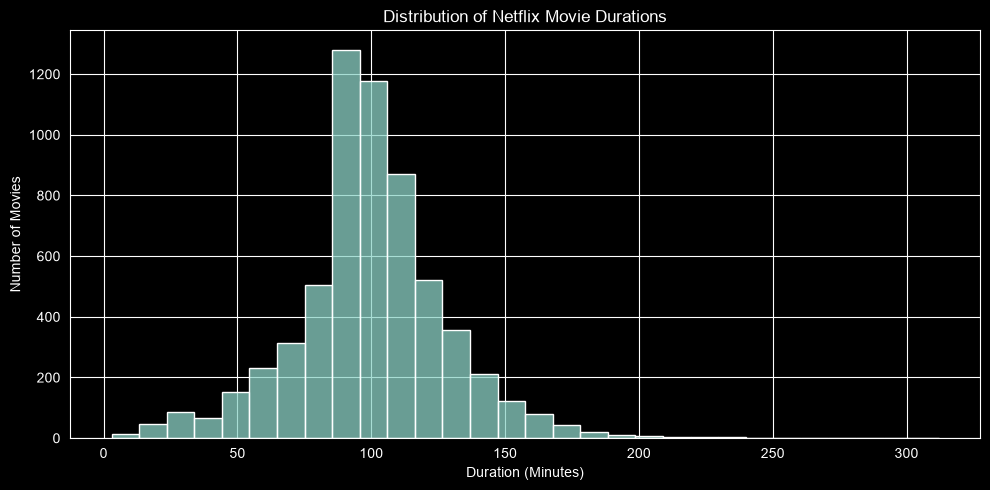

In [60]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=movies,
    x="duration_minutes",
    bins=30
)
plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

### Task 7A: Movie Duration Analysis — Key Findings

- Movie durations are concentrated mainly between approximately 80 and 120 minutes.
- The highest frequency appears around the 90–100 minute range.
- Relatively few movies have durations exceeding 150 minutes.
- **Business implication:** The catalog contains many movies with runtimes around 1.5–2 hours. Duration analysis helps describe the content available in the catalog.

**Limitation:** This analysis describes movie runtimes only; it does not show which durations viewers prefer or which movies perform best.

In [61]:
tv_shows["seasons"] = (
    tv_shows["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)
print(tv_shows["seasons"].describe())
print("\nSeason counts:")
print(tv_shows["seasons"].value_counts().sort_index())

count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: seasons, dtype: float64

Season counts:
seasons
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64


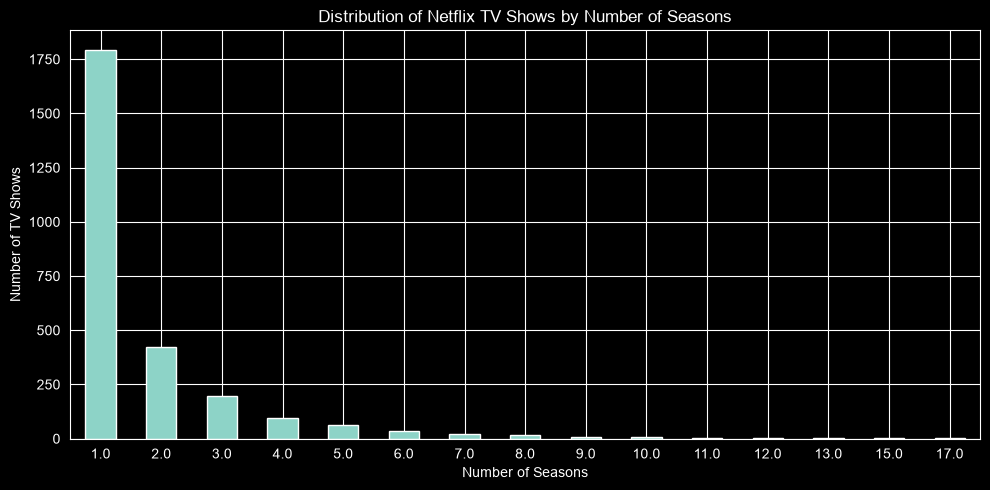

In [62]:
season_counts = tv_shows["seasons"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
season_counts.plot(kind="bar")

plt.title("Distribution of Netflix TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Task 7B: TV Show Season Analysis — Key Findings

- Most TV Shows in the dataset have one season, with 1,793 titles in this category.
- One-season shows account for approximately 67% of all TV Shows.
- The number of shows decreases as the number of seasons increases.
- **Business implication:** The catalog is heavily represented by one-season TV Shows. Further analysis by genre and release year could help describe this pattern in greater detail.

**Limitation:** Season counts do not indicate whether a show was cancelled, completed, or popular with viewers.

# Overall Exploratory Data Analysis (EDA) Summary

## Project Overview

The Netflix dataset contains 8,807 titles and 12 columns. The analysis examined content types, release years, catalog addition dates, ratings, countries, genres, and durations.

## Key Findings

### 1. Content Type
- Movies: 6,131 (69.62%).
- TV Shows: 2,676 (30.38%).
- Movies represent the larger share of the catalog.

### 2. Content Release Trends
- Release years range from 1925 to 2021.
- The median release year is 2017.
- The dataset contains a strong concentration of titles released during the 2010s.

### 3. Catalog Addition Trends
- Catalog additions peaked in 2019, with 2,016 titles.
- Additions declined in 2020 and 2021.

### 4. Content Ratings
- TV-MA is the most common rating, with 3,207 titles.
- TV-14 is the second most common, with 2,160 titles.
- Together, these categories account for approximately 60.9% of the catalog.

### 5. Country Analysis
- The United States has the highest number of title-country associations, followed by India and the United Kingdom.
- Titles may be associated with multiple countries.

### 6. Genre Analysis
- International Movies, Dramas, and Comedies are the most frequent categories.
- The catalog contains a variety of international, family-oriented, and other content categories.

### 7. Duration Analysis
- Movie durations are concentrated around 80–120 minutes.
- Approximately 67% of TV Shows have one season.

## Business Implications

- The catalog has a larger representation of Movies than TV Shows.
- Recent-release titles are strongly represented.
- Ratings, countries, genres, and durations provide different ways to understand the catalog's composition.
- These findings can guide further descriptive analysis and help organize an interactive Power BI dashboard.

## Limitations

- The dataset contains catalog metadata, not actual viewing hours, subscriber behavior, or revenue.
- Country and genre counts can overlap because a title may have multiple associations.
- The analysis describes patterns in the available dataset and does not establish the causes behind those patterns.

## Conclusion

The EDA stage identifies major patterns in the Netflix catalog and provides a foundation for dashboard development. The next step is to use these findings to build an interactive Power BI dashboard with clear KPIs, filters, and visualizations.